# micro:bit Flood Alert: Pre-Test and Post-Test Analysis

This notebook examines participant scores and question-level changes for
the micro:bit Flood Alert workshop.

The pre-test and post-test use identical questions, allowing paired
comparisons of scores and individual responses.

One participant has X recorded for all five post-test answers. Because
the workbook does not define X, the main analysis includes only participants
with valid A–D responses to all ten questions. The unresolved record is
retained and reported separately.

A sensitivity comparison also shows results when X is scored as incorrect,
as in the workbook. Observed changes do not establish that the workshop
alone caused changes in performance.

In [2]:
from pathlib import Path
from textwrap import fill

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

TRACK = "microbit_flood"
TITLE = "micro:bit Flood Alert"

# Locate the project whether Jupyter starts in the project or notebooks folder.
ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "data" / "processed").is_dir()),
    None
)

if ROOT is None:
    raise FileNotFoundError(
        "Cannot locate data/processed. Open this notebook inside your project."
    )

DATA = ROOT / "data" / "processed"
FIGURES = ROOT / "outputs" / "figures" / TRACK
TABLES = ROOT / "outputs" / "tables" / TRACK

FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

PRE_COLOR = "#7952B3"
POST_COLOR = "#E88932"

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

def save_figure(fig, filename):
    fig.tight_layout()
    fig.savefig(FIGURES / filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("Data folder:", DATA)

Data folder: c:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\OCTOBER_3_DATA\data\processed


In [3]:
df = pd.read_csv(
    DATA / "microbit_flood.csv",
    dtype={"participant_id": "string"},
)

reference = pd.read_csv(DATA / "question_reference.csv")
keys = reference.loc[reference["track"].eq(TRACK)].copy()

pre_cols = [f"pre_q{i}" for i in range(1, 6)]
post_cols = [f"post_q{i}" for i in range(1, 6)]
answer_cols = pre_cols + post_cols

required = ["participant_id", "track", *answer_cols]
missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

if df.empty:
    raise ValueError("The Flood dataset is empty.")

if df["participant_id"].fillna("").str.strip().eq("").any():
    raise ValueError("Missing participant IDs.")

if df["participant_id"].duplicated().any():
    raise ValueError("Duplicate participant IDs must be resolved.")

if not df["track"].eq(TRACK).all():
    raise ValueError("The dataset contains another track.")

# Preserve original responses in df; use normalized values for analysis.
answers = df[answer_cols].apply(
    lambda col: col.astype("string").str.strip().str.upper()
)

keys["phase"] = keys["phase"].astype(str).str.strip().str.lower()
keys["question_number"] = pd.to_numeric(
    keys["question"].astype(str).str.extract(r"(\d+)", expand=False),
    errors="raise",
).astype(int)

keys["answer_key_raw"] = (
    keys["answer_key_raw"].astype("string").str.strip().str.upper()
)

expected = {(phase, q) for phase in ["pre", "post"] for q in range(1, 6)}
actual = set(zip(keys["phase"], keys["question_number"]))

if len(keys) != 10 or actual != expected:
    raise ValueError("Expected exactly one answer key for each phase and question.")

if not keys["answer_key_raw"].isin(list("ABCD")).all():
    raise ValueError("An answer key is unresolved or invalid.")

key_map = keys.set_index(["phase", "question_number"])["answer_key_raw"]
skills = (
    keys.loc[keys["phase"].eq("pre")]
    .set_index("question_number")["skill"]
    .to_dict()
)

for q in range(1, 6):
    if key_map[("pre", q)] != key_map[("post", q)]:
        raise ValueError(f"Pre/post keys differ for Q{q}; review comparability.")

valid = answers.isin(list("ABCD"))
complete_mask = valid.all(axis=1)

audit = df[["participant_id"]].copy()
audit["x_count"] = answers.eq("X").fillna(False).sum(axis=1)
audit["unresolved_answer_count"] = (~valid).sum(axis=1)
audit["included_in_paired_analysis"] = complete_mask

print(f"Total participants: {len(df)}")
print(f"Complete pre/post responses: {complete_mask.sum()}")
print(f"Records needing review: {(~complete_mask).sum()}")

display(keys[["phase", "question_number", "answer_key_raw", "skill"]])
display(audit.loc[~complete_mask])
display(df.loc[~complete_mask, ["participant_id", *answer_cols]])

Total participants: 26
Complete pre/post responses: 25
Records needing review: 1


,phase,question_number,answer_key_raw,skill
30,pre,1,C,Decomposition
31,pre,2,B,Pattern Recognition
32,pre,3,D,Abstraction
33,pre,4,A,Conditional logic / algorithm
34,pre,5,B,Debugging
35,post,1,C,Decomposition
36,post,2,B,Pattern Recognition
37,post,3,D,Abstraction
38,post,4,A,Conditional logic / algorithm
39,post,5,B,Debugging


,participant_id,x_count,unresolved_answer_count,included_in_paired_analysis
17,9AF69A27,5,5,False


,participant_id,pre_q1,pre_q2,pre_q3,pre_q4,pre_q5,post_q1,post_q2,post_q3,post_q4,post_q5
17,9AF69A27,C,B,C,A,B,X,X,X,X,X


## Scoring and analysis groups

Each correct answer earns one point. A complete assessment has five
questions, so each point represents 20 percentage points.

The main analysis uses the same participants for pre-test and post-test
calculations and includes only complete A–D response pairs.

For the separate sensitivity comparison, X is counted as incorrect.
This reproduces the workbook's scoring treatment without claiming that
X is a confirmed incorrect response.

In [4]:
# Correctness is missing for unresolved responses.
correctness = pd.DataFrame(index=df.index)

for phase in ["pre", "post"]:
    for q in range(1, 6):
        col = f"{phase}_q{q}"
        correctness[col] = (
            answers[col].eq(key_map[(phase, q)])
            .astype("Float64")
            .where(valid[col])
        )

paired = df.loc[complete_mask, ["participant_id"]].copy()

for phase, cols in [("pre", pre_cols), ("post", post_cols)]:
    paired[f"{phase}_correct"] = (
        correctness.loc[complete_mask, cols]
        .sum(axis=1, min_count=5)
        .astype(int)
    )
    paired[f"{phase}_score_pct"] = paired[f"{phase}_correct"] * 20

paired["change_pp"] = paired["post_score_pct"] - paired["pre_score_pct"]

if paired.empty:
    raise ValueError("No complete pairs are available for analysis.")

# Allow only A–D or X in the workbook-scoring sensitivity group.
# Other unresolved values are not silently converted to zero.
sensitivity_mask = answers.isin(list("ABCD") + ["X"]).all(axis=1)
sensitivity = df.loc[sensitivity_mask, ["participant_id"]].copy()

for phase, cols in [("pre", pre_cols), ("post", post_cols)]:
    sensitivity[f"{phase}_correct"] = (
        correctness.loc[sensitivity_mask, cols].fillna(0).sum(axis=1)
    )
    sensitivity[f"{phase}_score_pct"] = (
        sensitivity[f"{phase}_correct"] * 20
    )

sensitivity["change_pp"] = (
    sensitivity["post_score_pct"] - sensitivity["pre_score_pct"]
)

def summarize_group(frame, label):
    return {
        "analysis": label,
        "participants": len(frame),
        "pre_mean_pct": frame["pre_score_pct"].mean(),
        "post_mean_pct": frame["post_score_pct"].mean(),
        "mean_change_pp": frame["change_pp"].mean(),
    }

sensitivity_summary = pd.DataFrame([
    summarize_group(paired, "Complete A–D pairs — main analysis"),
    summarize_group(sensitivity, "A–D and X; X scored zero — sensitivity"),
])

display(sensitivity_summary.round(2))

# Verify the reconstructed sensitivity scores against stored workbook scores.
checks = []
for calculated, stored in [
    ("pre_correct", "pre_correct_workbook"),
    ("post_correct", "post_correct_workbook"),
    ("pre_score_pct", "pre_score_pct_workbook"),
    ("post_score_pct", "post_score_pct_workbook"),
    ("change_pp", "change_pp_workbook"),
]:
    if stored in df.columns:
        expected_values = pd.to_numeric(
            df.loc[sensitivity.index, stored], errors="coerce"
        ).to_numpy(dtype=float)

        matches = np.isclose(
            sensitivity[calculated].to_numpy(dtype=float),
            expected_values,
            atol=1e-8,
            equal_nan=False,
        )

        checks.append({
            "field": stored,
            "matching": int(matches.sum()),
            "mismatching_or_missing": int((~matches).sum()),
        })

verification = pd.DataFrame(checks)
display(verification)

if not verification.empty and verification["mismatching_or_missing"].sum():
    raise ValueError("Workbook score differences found. Review before continuing.")

,analysis,participants,pre_mean_pct,post_mean_pct,mean_change_pp
0,Complete A–D pairs — main analysis,25,67.20,66.40,-0.80
1,A–D and X; X scored zero — sensitivity,26,67.69,63.85,-3.85


,field,matching,mismatching_or_missing
0,pre_correct_workbook,26,0
1,post_correct_workbook,26,0
2,pre_score_pct_workbook,26,0
3,post_score_pct_workbook,26,0
4,change_pp_workbook,26,0


## Overall scores and participant changes

The following figures show average scores, the number of participants
whose scores increased or decreased, and the distribution of scores.

All figures use complete pre/post pairs. Percentage-point changes are
calculated as post-test percentage minus pre-test percentage.

,phase,participants,mean_correct,median_correct,sd_correct,minimum_correct,maximum_correct,mean_score_pct
0,Pre,25,3.36,4.0,0.91,2,5,67.2
1,Post,25,3.32,3.0,0.80,2,5,66.4


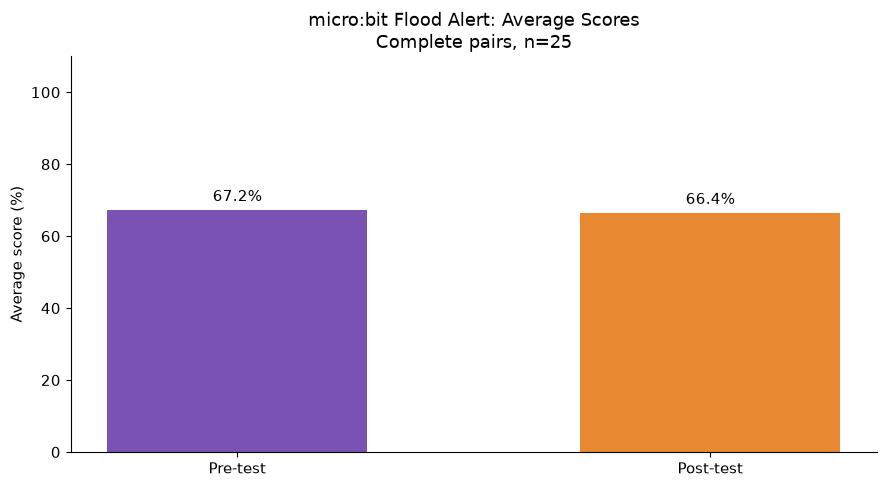

,change_group,participants,percentage
0,Higher,7,28.0
1,Unchanged,12,48.0
2,Lower,6,24.0


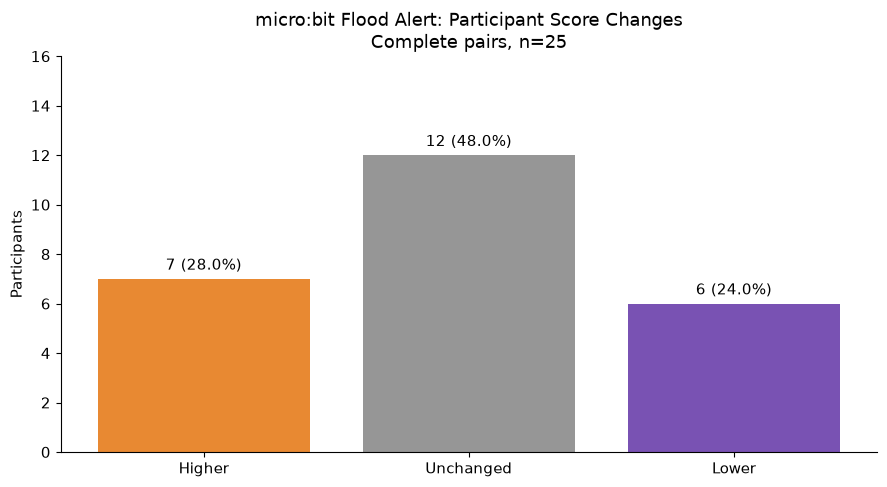

,correct_answers,pre,post
0,0,0,0
1,1,0,0
2,2,6,4
3,3,5,10
4,4,13,10
5,5,1,1


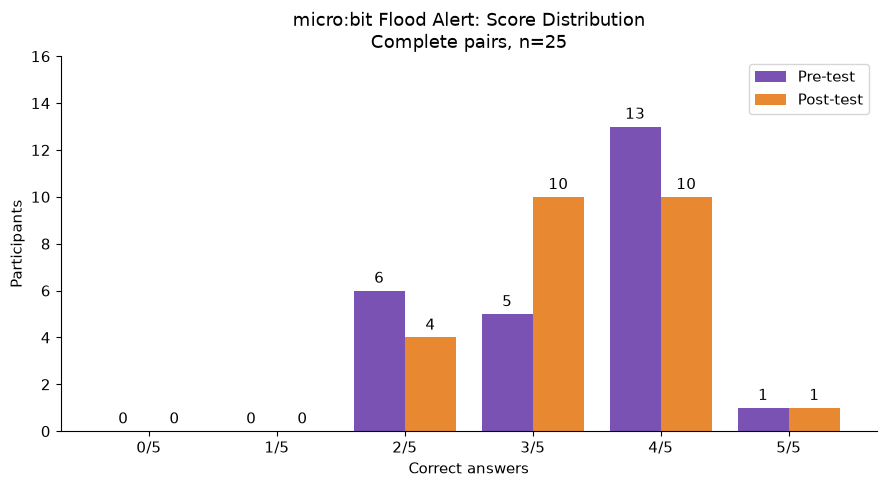

In [5]:
n = len(paired)

summary = pd.DataFrame([
    {
        "phase": phase.title(),
        "participants": n,
        "mean_correct": paired[f"{phase}_correct"].mean(),
        "median_correct": paired[f"{phase}_correct"].median(),
        "sd_correct": paired[f"{phase}_correct"].std(),
        "minimum_correct": paired[f"{phase}_correct"].min(),
        "maximum_correct": paired[f"{phase}_correct"].max(),
        "mean_score_pct": paired[f"{phase}_score_pct"].mean(),
    }
    for phase in ["pre", "post"]
])

display(summary.round(2))

# Figure 1: average scores
fig, ax = plt.subplots()
bars = ax.bar(
    ["Pre-test", "Post-test"],
    summary["mean_score_pct"],
    color=[PRE_COLOR, POST_COLOR],
    width=0.55,
)
ax.bar_label(bars, fmt="%.1f%%", padding=4)
ax.set_ylim(0, 110)
ax.set_ylabel("Average score (%)")
ax.set_title(f"{TITLE}: Average Scores\nComplete pairs, n={n}")
save_figure(fig, "01_average_scores.png")

# Figure 2: participant changes
paired["change_group"] = np.select(
    [paired["change_pp"].gt(0), paired["change_pp"].lt(0)],
    ["Higher", "Lower"],
    default="Unchanged",
)

changes = (
    paired["change_group"].value_counts()
    .reindex(["Higher", "Unchanged", "Lower"], fill_value=0)
    .rename_axis("change_group")
    .reset_index(name="participants")
)
changes["percentage"] = changes["participants"] / n * 100
display(changes.round(2))

fig, ax = plt.subplots()
bars = ax.bar(
    changes["change_group"],
    changes["participants"],
    color=[POST_COLOR, "#969696", PRE_COLOR],
)
ax.bar_label(
    bars,
    labels=[
        f"{count} ({pct:.1f}%)"
        for count, pct in zip(changes["participants"], changes["percentage"])
    ],
    padding=4,
)
ax.set_ylim(0, max(changes["participants"]) + 4)
ax.set_ylabel("Participants")
ax.yaxis.get_major_locator().set_params(integer=True)
ax.set_title(f"{TITLE}: Participant Score Changes\nComplete pairs, n={n}")
save_figure(fig, "02_participant_changes.png")

# Figure 3: score distributions
distribution = pd.DataFrame({"correct_answers": range(6)})

for phase in ["pre", "post"]:
    distribution[phase] = (
        paired[f"{phase}_correct"].value_counts()
        .reindex(range(6), fill_value=0).to_numpy()
    )

display(distribution)

x = np.arange(6)
fig, ax = plt.subplots()
for offset, phase, color in [
    (-0.2, "pre", PRE_COLOR),
    (0.2, "post", POST_COLOR),
]:
    bars = ax.bar(
        x + offset, distribution[phase], width=0.4,
        label=f"{phase.title()}-test", color=color,
    )
    ax.bar_label(bars, padding=3)

ax.set_xticks(x, [f"{i}/5" for i in x])
ax.set_ylim(0, distribution[["pre", "post"]].to_numpy().max() + 3)
ax.set_xlabel("Correct answers")
ax.set_ylabel("Participants")
ax.yaxis.get_major_locator().set_params(integer=True)
ax.set_title(f"{TITLE}: Score Distribution\nComplete pairs, n={n}")
ax.legend()
save_figure(fig, "03_score_distribution.png")

## Question-level results and response transitions

Correct-answer rates are compared using the same complete-pair group.

Each question is also classified into four response transitions:

- Incorrect to correct
- Correct to incorrect
- Correct in both assessments
- Incorrect in both assessments

These results describe performance on each individual question. One
question alone is insufficient to establish mastery of an entire skill.

,question,skill,participants,pre_correct,post_correct,pre_pct,post_pct,change_pp
0,Q1,Decomposition,25,14,20,56.0,80.0,24.0
1,Q2,Pattern Recognition,25,19,18,76.0,72.0,-4.0
2,Q3,Abstraction,25,3,1,12.0,4.0,-8.0
3,Q4,Conditional logic / algorithm,25,23,20,92.0,80.0,-12.0
4,Q5,Debugging,25,25,24,100.0,96.0,-4.0


,question,skill,wrong_to_right,right_to_wrong,right_both,wrong_both,net_correct_change
0,Q1,Decomposition,6,0,14,5,6
1,Q2,Pattern Recognition,2,3,16,4,-1
2,Q3,Abstraction,0,2,1,22,-2
3,Q4,Conditional logic / algorithm,0,3,20,2,-3
4,Q5,Debugging,0,1,24,0,-1


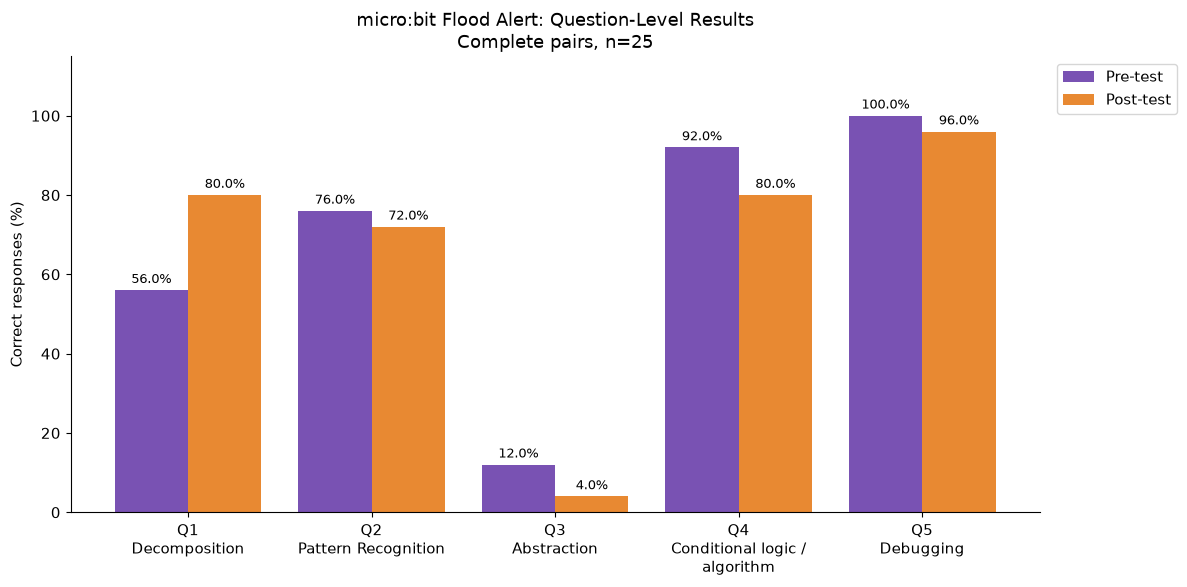

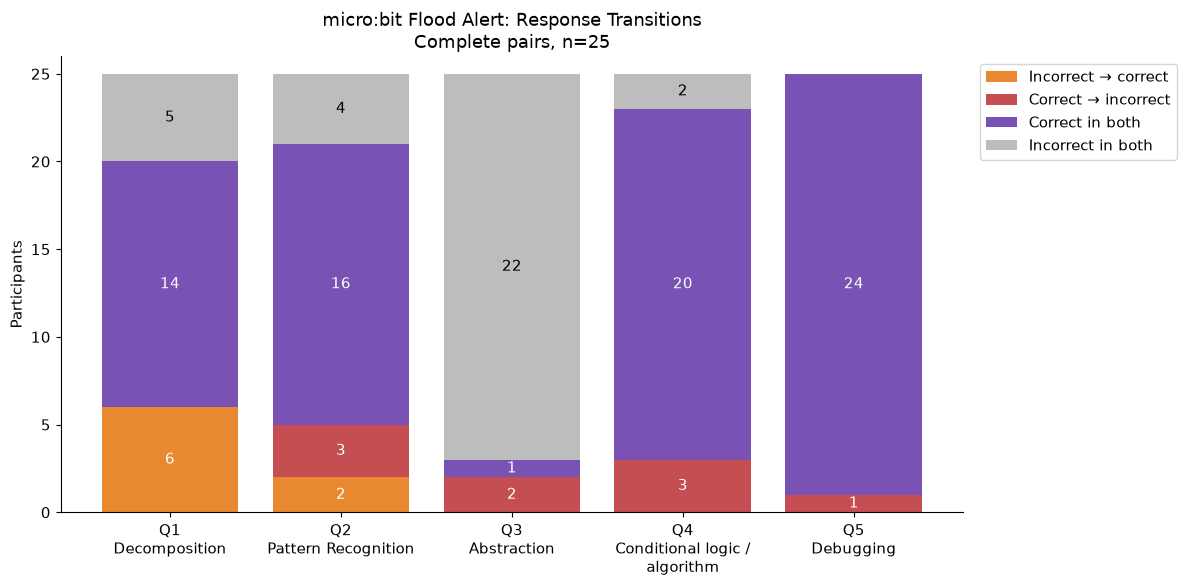

In [6]:
item_rows = []
transition_rows = []

for q in range(1, 6):
    pre = correctness.loc[complete_mask, f"pre_q{q}"].astype(int)
    post = correctness.loc[complete_mask, f"post_q{q}"].astype(int)

    item_rows.append({
        "question": f"Q{q}",
        "skill": skills[q],
        "participants": n,
        "pre_correct": int(pre.sum()),
        "post_correct": int(post.sum()),
        "pre_pct": pre.mean() * 100,
        "post_pct": post.mean() * 100,
        "change_pp": (post.mean() - pre.mean()) * 100,
    })

    transition_rows.append({
        "question": f"Q{q}",
        "skill": skills[q],
        "wrong_to_right": int(((pre == 0) & (post == 1)).sum()),
        "right_to_wrong": int(((pre == 1) & (post == 0)).sum()),
        "right_both": int(((pre == 1) & (post == 1)).sum()),
        "wrong_both": int(((pre == 0) & (post == 0)).sum()),
    })

items = pd.DataFrame(item_rows)
transitions = pd.DataFrame(transition_rows)
transitions["net_correct_change"] = (
    transitions["wrong_to_right"] - transitions["right_to_wrong"]
)

display(items.round(2))
display(transitions)

labels = [
    f"{row.question}\n{fill(str(row.skill), 20)}"
    for row in items.itertuples()
]

# Figure 4: question-level correctness
x = np.arange(len(items))
fig, ax = plt.subplots(figsize=(12, 6))

for offset, phase, color in [
    (-0.2, "pre", PRE_COLOR),
    (0.2, "post", POST_COLOR),
]:
    bars = ax.bar(
        x + offset, items[f"{phase}_pct"], width=0.4,
        label=f"{phase.title()}-test", color=color,
    )
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)

ax.set_xticks(x, labels)
ax.set_ylim(0, 115)
ax.set_ylabel("Correct responses (%)")
ax.set_title(f"{TITLE}: Question-Level Results\nComplete pairs, n={n}")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
save_figure(fig, "04_question_correctness.png")

# Figure 5: response transitions
fig, ax = plt.subplots(figsize=(12, 6))
bottom = np.zeros(len(transitions))

transition_styles = [
    ("wrong_to_right", "Incorrect → correct", POST_COLOR),
    ("right_to_wrong", "Correct → incorrect", "#C44E52"),
    ("right_both", "Correct in both", PRE_COLOR),
    ("wrong_both", "Incorrect in both", "#BDBDBD"),
]

for column, label, color in transition_styles:
    counts = transitions[column].to_numpy()
    bars = ax.bar(x, counts, bottom=bottom, label=label, color=color)

    ax.bar_label(
        bars,
        labels=[str(v) if v else "" for v in counts],
        label_type="center",
        color="black" if column == "wrong_both" else "white",
    )
    bottom += counts

ax.set_xticks(x, labels)
ax.set_ylim(0, n + 1)
ax.set_ylabel("Participants")
ax.yaxis.get_major_locator().set_params(integer=True)
ax.set_title(f"{TITLE}: Response Transitions\nComplete pairs, n={n}")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
save_figure(fig, "05_response_transitions.png")

In [7]:
pre_mean = paired["pre_score_pct"].mean()
post_mean = paired["post_score_pct"].mean()
mean_change = paired["change_pp"].mean()

higher = int(paired["change_pp"].gt(0).sum())
unchanged = int(paired["change_pp"].eq(0).sum())
lower = int(paired["change_pp"].lt(0).sum())

weakest = items.loc[items["post_pct"].eq(items["post_pct"].min())]
strongest = items.loc[items["post_pct"].eq(items["post_pct"].max())]

def describe_items(frame):
    return "; ".join(
        f"{r.question} ({r.skill}): {r.post_pct:.1f}%"
        for r in frame.itertuples()
    )

item_lines = "\n".join(
    f"- **{r.question} — {r.skill}:** "
    f"{r.pre_pct:.1f}% pre-test → {r.post_pct:.1f}% post-test "
    f"({r.change_pp:+.1f} percentage points)."
    for r in items.itertuples()
)

sensitivity_result = sensitivity_summary.iloc[1]

findings_md = f"""
## Overall findings

The dataset contains **{len(df)} participants**. The main paired analysis
includes **{n} participants** with complete A–D responses and excludes
**{len(df) - n} unresolved record(s)** from both phases of the comparison.

The average score changed from **{pre_mean:.1f}%** to
**{post_mean:.1f}%**, a difference of **{mean_change:+.1f} percentage points**.

- Higher post-test scores: **{higher} ({higher / n:.1%})**
- Unchanged scores: **{unchanged} ({unchanged / n:.1%})**
- Lower post-test scores: **{lower} ({lower / n:.1%})**

## Question-level findings

{item_lines}

The lowest post-test correctness was **{describe_items(weakest)}**.

The highest post-test correctness was **{describe_items(strongest)}**.

Across the five questions, there were
**{transitions["wrong_to_right"].sum()} incorrect-to-correct transitions**
and **{transitions["right_to_wrong"].sum()} correct-to-incorrect transitions**.
These are question-response counts, not counts of distinct participants.

## Effect of the unresolved responses

When X is scored as incorrect, the sensitivity group contains
**{int(sensitivity_result["participants"])} participants**. Its average
scores are **{sensitivity_result["pre_mean_pct"]:.1f}%** before and
**{sensitivity_result["post_mean_pct"]:.1f}%** after, a change of
**{sensitivity_result["mean_change_pp"]:+.1f} percentage points**.

The complete-pair result is the primary result. The sensitivity result
documents the effect of the workbook's scoring treatment; it does not
confirm the meaning of X.

## Limitations

The group is small, each assessment has only five questions, and there
is no comparison group. Repeating identical questions may also influence
post-test responses. Excluding unresolved records may affect how well
the results represent all participants.

The findings describe immediate assessment performance, not long-term
retention or a proven causal effect of the workshop.
"""

display(Markdown(findings_md))


## Overall findings

The dataset contains **26 participants**. The main paired analysis
includes **25 participants** with complete A–D responses and excludes
**1 unresolved record(s)** from both phases of the comparison.

The average score changed from **67.2%** to
**66.4%**, a difference of **-0.8 percentage points**.

- Higher post-test scores: **7 (28.0%)**
- Unchanged scores: **12 (48.0%)**
- Lower post-test scores: **6 (24.0%)**

## Question-level findings

- **Q1 — Decomposition:** 56.0% pre-test → 80.0% post-test (+24.0 percentage points).
- **Q2 — Pattern Recognition:** 76.0% pre-test → 72.0% post-test (-4.0 percentage points).
- **Q3 — Abstraction:** 12.0% pre-test → 4.0% post-test (-8.0 percentage points).
- **Q4 — Conditional logic / algorithm:** 92.0% pre-test → 80.0% post-test (-12.0 percentage points).
- **Q5 — Debugging:** 100.0% pre-test → 96.0% post-test (-4.0 percentage points).

The lowest post-test correctness was **Q3 (Abstraction): 4.0%**.

The highest post-test correctness was **Q5 (Debugging): 96.0%**.

Across the five questions, there were
**8 incorrect-to-correct transitions**
and **9 correct-to-incorrect transitions**.
These are question-response counts, not counts of distinct participants.

## Effect of the unresolved responses

When X is scored as incorrect, the sensitivity group contains
**26 participants**. Its average
scores are **67.7%** before and
**63.8%** after, a change of
**-3.8 percentage points**.

The complete-pair result is the primary result. The sensitivity result
documents the effect of the workbook's scoring treatment; it does not
confirm the meaning of X.

## Limitations

The group is small, each assessment has only five questions, and there
is no comparison group. Repeating identical questions may also influence
post-test responses. Excluding unresolved records may affect how well
the results represent all participants.

The findings describe immediate assessment performance, not long-term
retention or a proven causal effect of the workshop.


In [8]:
priority_items = items.sort_values(
    ["post_pct", "question"]
).head(3)

priority_lines = "\n".join(
    f"- **{r.question} — {r.skill}:** "
    f"Review this item and its distractors; "
    f"{int(r.participants - r.post_correct)} of {int(r.participants)} "
    f"participants answered incorrectly on the post-test "
    f"({r.post_pct:.1f}% correct)."
    for r in priority_items.itertuples()
)

declines = items.loc[items["change_pp"].lt(0)]

decline_text = (
    "\n".join(
        f"- Review **{r.question} ({r.skill})**, which decreased by "
        f"{abs(r.change_pp):.1f} percentage points. Inspect answer choices "
        f"and question wording before proposing an explanation."
        for r in declines.itertuples()
    )
    if not declines.empty
    else "No question showed a lower correct-answer rate in the paired group."
)

recommendations_md = f"""
## Recommendations

### Review the lowest post-test results

The following are relative priorities within this assessment, rather than
a formal pass/fail classification:

{priority_lines}

Use a practical flood-alert exercise that asks participants to identify
the sensor input, divide the system into tasks, trace threshold decisions,
and debug an incorrect alert.

### Examine decreases

{decline_text}

### Resolve the X responses

Confirm the meaning of X with the data owner or original assessment
records. Preserve the original entries and document any approved scoring
change before updating the analysis.

### Check retention

Use a later assessment with comparable questions and a practical task to
examine whether participants retain and apply the concepts.

### Later machine-learning analysis

Use pre-test information to predict post-test scores. Do not use post-test
answers or score changes as input features.

Keep participants with unresolved post-test outcomes out of supervised
model evaluation until those outcomes are confirmed. Evaluate predictions
on held-out participants and compare with simple baselines, including
predicting no change and predicting the training group's mean post-test
score.

Report mean absolute error in score points or percentage points. With
only {n} complete pairs, results should be treated as exploratory.
"""

display(Markdown(recommendations_md))


## Recommendations

### Review the lowest post-test results

The following are relative priorities within this assessment, rather than
a formal pass/fail classification:

- **Q3 — Abstraction:** Review this item and its distractors; 24 of 25 participants answered incorrectly on the post-test (4.0% correct).
- **Q2 — Pattern Recognition:** Review this item and its distractors; 7 of 25 participants answered incorrectly on the post-test (72.0% correct).
- **Q1 — Decomposition:** Review this item and its distractors; 5 of 25 participants answered incorrectly on the post-test (80.0% correct).

Use a practical flood-alert exercise that asks participants to identify
the sensor input, divide the system into tasks, trace threshold decisions,
and debug an incorrect alert.

### Examine decreases

- Review **Q2 (Pattern Recognition)**, which decreased by 4.0 percentage points. Inspect answer choices and question wording before proposing an explanation.
- Review **Q3 (Abstraction)**, which decreased by 8.0 percentage points. Inspect answer choices and question wording before proposing an explanation.
- Review **Q4 (Conditional logic / algorithm)**, which decreased by 12.0 percentage points. Inspect answer choices and question wording before proposing an explanation.
- Review **Q5 (Debugging)**, which decreased by 4.0 percentage points. Inspect answer choices and question wording before proposing an explanation.

### Resolve the X responses

Confirm the meaning of X with the data owner or original assessment
records. Preserve the original entries and document any approved scoring
change before updating the analysis.

### Check retention

Use a later assessment with comparable questions and a practical task to
examine whether participants retain and apply the concepts.

### Later machine-learning analysis

Use pre-test information to predict post-test scores. Do not use post-test
answers or score changes as input features.

Keep participants with unresolved post-test outcomes out of supervised
model evaluation until those outcomes are confirmed. Evaluate predictions
on held-out participants and compare with simple baselines, including
predicting no change and predicting the training group's mean post-test
score.

Report mean absolute error in score points or percentage points. With
only 25 complete pairs, results should be treated as exploratory.


In [10]:
interpretation_md = """
## Interpretation of the results

Average performance was nearly unchanged, decreasing from 67.2% to
66.4%. Across the 25 participants and five questions, this represents
one fewer correct response overall: 84 before and 83 after.

Although seven participants improved and six scored lower, the size
of their individual changes also matters. Counting participants alone
does not determine whether the group average increases.

### Different patterns across questions

Decomposition showed the clearest improvement, increasing from 56% to
80%. Six participants changed from incorrect to correct, while none
changed from correct to incorrect.

Abstraction requires the most urgent review. Only one participant
answered correctly after the workshop. Twenty-two answered incorrectly
in both assessments, and two changed from correct to incorrect.
Check the original question, answer key, and recorded responses before
attributing this result solely to difficulty understanding abstraction.

Conditional logic decreased from 92% to 80%. Three participants changed
from correct to incorrect, suggesting that this item also deserves review.

Debugging remained the strongest post-test result at 96%. Its 100%
pre-test correctness left no room for an increase on this item.

### Effect of the unresolved record

The complete-pair analysis shows a change of -0.80 percentage points.
Including the unresolved post-test as zero changes the result to
-3.85 percentage points.

The treatment of this record therefore affects the apparent size of
the decline. Report the 25-participant result as the primary analysis
and label the 26-participant result as the sensitivity comparison.
"""

# Avoid duplicating this section if the cell is run more than once.
findings_md = (
    findings_md.split("\n## Interpretation of the results")[0].rstrip()
    + "\n\n"
    + interpretation_md.strip()
)

display(Markdown(interpretation_md))

exports = {
    "participant_audit": audit,
    "paired_participant_scores": paired,
    "score_summary": summary,
    "participant_changes": changes,
    "score_distribution": distribution,
    "item_comparison": items,
    "response_transitions": transitions,
    "sensitivity_comparison": sensitivity_summary,
    "workbook_verification": verification,
}

for name, table in exports.items():
    table.to_csv(
        TABLES / f"{TRACK}_{name}.csv",
        index=False,
    )

findings_path = TABLES / f"{TRACK}_findings.md"
findings_path.write_text(
    findings_md + "\n\n" + recommendations_md,
    encoding="utf-8",
)

print(f"Saved {len(exports)} result tables.")
print("Figures:", FIGURES)
print("Findings:", findings_path)


## Interpretation of the results

Average performance was nearly unchanged, decreasing from 67.2% to
66.4%. Across the 25 participants and five questions, this represents
one fewer correct response overall: 84 before and 83 after.

Although seven participants improved and six scored lower, the size
of their individual changes also matters. Counting participants alone
does not determine whether the group average increases.

### Different patterns across questions

Decomposition showed the clearest improvement, increasing from 56% to
80%. Six participants changed from incorrect to correct, while none
changed from correct to incorrect.

Abstraction requires the most urgent review. Only one participant
answered correctly after the workshop. Twenty-two answered incorrectly
in both assessments, and two changed from correct to incorrect.
Check the original question, answer key, and recorded responses before
attributing this result solely to difficulty understanding abstraction.

Conditional logic decreased from 92% to 80%. Three participants changed
from correct to incorrect, suggesting that this item also deserves review.

Debugging remained the strongest post-test result at 96%. Its 100%
pre-test correctness left no room for an increase on this item.

### Effect of the unresolved record

The complete-pair analysis shows a change of -0.80 percentage points.
Including the unresolved post-test as zero changes the result to
-3.85 percentage points.

The treatment of this record therefore affects the apparent size of
the decline. Report the 25-participant result as the primary analysis
and label the 26-participant result as the sensitivity comparison.


Saved 9 result tables.
Figures: c:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\OCTOBER_3_DATA\outputs\figures\microbit_flood
Findings: c:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\OCTOBER_3_DATA\outputs\tables\microbit_flood\microbit_flood_findings.md
